# Evaluate Source Reconstruction Methods Using Simulations

## 🧪 - Experiment setup
- `fwd`: Forward solution
- `stc_files`: Files of source reconstruction results
- `gt`: Ground truth

In [21]:
import mindmap as mm

dm = mm.io.TutoManager("../config.yml")
sub = "simf10"

fwd = dm.load(sub, "fwd", desc="inv")
stc_dir = dm.roots["mm"]/f"sub-{sub}"/"stc"

## 🧬 - Data Processing
Estimate regularization parameter

In [22]:
metrics = mm.metric.MetricSuite("Simulation Evaluation", context = {"src": fwd["src"]})

for sample in mm.analysis.inverse.stream_source_solutions(stc_dir, target_method = ["sloreta", "wcset", "cset", "dspm"]):
    # extract valuable entities
    entities = sample["meta"]
    subject = entities.pop("subject")
    method = entities.pop("desc")
    for key in ["suffix", "extension"]:
        entities.pop(key, None)
    
    # load ground truth
    gold = dm.load(subject, "gold", **entities)

    # crop to the same range
    tmin, tmax = sample["stc"].times.min(), sample["stc"].times.max()
    gold = gold.crop(tmin, tmax)

    # correlation
    corr = mm.analysis.inverse.compute_stc_correlation(gold, sample["stc"], mode="spatial", method="pearson")
    metrics.register(method, "correlation", corr, times=sample["stc"].times)


In [ ]:
metrics.plot("correlation", x="times");


## 📦 Imports

In [15]:
import mindmap as mm
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import scipy as sp

# plot options
sns.set_theme(font_scale=1.5)
sns.set_style("whitegrid")

In [27]:
def compute_error(recon, area, src, brain, eeg, cras):
    """
    Compute source localisation at 50% rising phase and correlation at peak phase.

    Parameters
    ----------
    recon: mne.SourceEstimate.
        Reconstruction at 50% rising phase [0] and peak phase [1]

    area:
        Location of source. 

    src: mne.SourceSpace
        Dipole locations.

    brain:
        Ground truth.

    Returns
    -------
    dist: float
        Distance error to source location.

    corr: float
        Correlation with ground truth at peak phase.
    """
    # measure error distance
    estimate = mm.utils.select_source_estimate(recon, src, tp=0)
    dist     = mm.utils.measure_distance(estimate, area, cras=cras)

    # measure correlation
    peak_time = mm.utils.eeg_rising_phase(eeg, 1)

    idx = brain.time_as_index(peak_time)
    gt  = np.abs(brain.data[:,idx])
    gt  = (gt -gt.mean())/np.std(gt)

    if recon.data.shape[1] == 1:
        tmp = np.abs(recon.data.squeeze())

    else:
        idx = recon.time_as_index(peak_time)
        tmp = np.abs(recon.data[:,idx])

    tmp = (tmp - tmp.mean())/np.std(tmp)
    
    corr = np.sum(gt*tmp)/(gt.shape[0]-1)

    return dist, corr

def compute_corr(recon, brain):
    correlations = []

    for t in recon.times:
        idx = brain.time_as_index(t)
        gt  = np.abs(brain.data[:,idx])
        gt  = (gt - gt.mean())/np.std(gt)

        idx = recon.time_as_index(t)
        rec = np.abs(recon.data[:,idx])
        rec = (rec-rec.mean())/np.std(rec)

        corr = np.sum(gt*rec)/(gt.shape[0]-1)
        correlations.append(corr)

    return correlations

## 🧠 Data


📥 **<font color=pink>Inputs</font>**
- `fwd`: Forward operator
- `eeg`: Template EEG
- `sc`: Structural connectome
- `cst`: Connectome spectrum transform 
- `parc`: Parcellation 
- `ctx`: Cortical mask
- `cras`: Translation (FreeSurfer -> MRI)

🛠️ **<font color=violet>Configuration</font>**:
- `fconfig`: Configuration file.

🛠️ **<font color=violet>Simulation options</font>**:
- `methods`: Names of source imaging methods 
- `N`: Number of different brain regions
- `rep`: Number of repetitions 

In [56]:
#################### Parameters ####################
# configuration
fconfig = "../../configurations/simf.yml"

# simulation
methods = ["cset", "sloreta"]
N       = 100
rep     = 1
#####################################################

# configuration
config = mm.io.read_config("../../configurations/simf.yml")
sub    = config["SUBS"][0]

# data
data = mm.io.read_dataset(sub, "fwd", "eeg", "sc", "cst", "parc", "cras", "ctx")

Coregistered EEG found
DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- parc
- eeg
- sc
- cras
- fwd
- ctx
- cst
Missing objects:


## ♾️ Loop

In [57]:
error = {m:[] for m in methods}
error["loc"] = []

# select source locations
#source_regions = mm.utils.select_sources(sub, spacing="ico1", mask=data["ctx"], cras=data["cras"])
#source_regions = data["parc"].label_points(source_regions)
src    = mm.utils.get_src_position(data["fwd"]["src"])*1000 + data["cras"]
labels = data["parc"].label_points(src)
labs   = np.unique(labels)

if N == "all":
    source_regions = labs 
else:
    source_regions = np.random.choice(labs, N, replace=False) 

# generate spike signal
spike = mm.utils.create_source_spike(
        duration = 1,                               # [s] 
        sfreq = data["eeg"].info["sfreq"],    # [Hz] 
        stype = "mex",                              # mexican hat signal 
        amplitude = 1e-8,                           # [A] (10-8 -> 10 [nA]) 
    )

# iterate through locations
for location in source_regions:
    
    area = data["parc"].create_mask(location)   # for localisation error

    spike_activity = mm.utils.generate_spike_activity(
        src      = data["fwd"]["src"],
        sc       = data["sc"],
        parc     = data["parc"],
        spike    = spike,
        location = location, 
        dw       = 0.25,        # propagation weight [0-1]
        dt       = 50,         # time delay [ms]
        sfreq    = data["eeg"].info["sfreq"],
        cras     = data["cras"],
    )

    # iterate through repetitions
    for r in range(rep):


        brain_noise, eeg_noise = mm.utils.generate_scaled_noise(
            data       = spike_activity,
            fwd        = data["fwd"],
            target_snr = 20,
            ratio      = 0.9, 
        )

        brain, eeg = mm.utils.simulate_eeg(
            brain_activity = spike_activity,
            fwd            = data["fwd"],
            eeg_temp       = data["eeg"],
            brain_noise    = brain_noise,
            eeg_noise      = eeg_noise, 
            sub            = sub,
        )

        hrp = mm.utils.eeg_rising_phase(eeg, 0.5)
        pp  = mm.utils.eeg_rising_phase(eeg, 1)

        # iterate through source reconstruction methods
        if "cset" in methods:
            recon = mm.cset(eeg=eeg, fwd=data["fwd"], cst=data["cst"], lam=0.01, dw=0.5, times=[hrp, pp], sub=sub)
            #dist, corr = compute_error(recon, area, data["fwd"]["src"], brain, eeg, cras=data["cras"])
            corr1, corr2 = compute_corr(recon, brain)
            #error["cset"].append((dist,corr))
            error["cset"].append((corr1, corr2))
            
        if "sloreta" in methods:
            recon = mm.sloreta(eeg=eeg, fwd=data["fwd"], lam=0.01, times=[hrp, pp])
            #dist, corr = compute_error(recon, area, data["fwd"]["src"], brain, eeg, cras=data["cras"])
            corr1, corr2 = compute_corr(recon, brain)
            #error["sloreta"].append((dist,corr))
            error["sloreta"].append((corr1, corr2))

        error["loc"].append(location)

EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projecti

## Visualize results

🌟 **Localization error**

Average difference:  7.989412253499335


WilcoxonResult(statistic=np.float64(4222.0), pvalue=np.float64(8.099104017028752e-59))

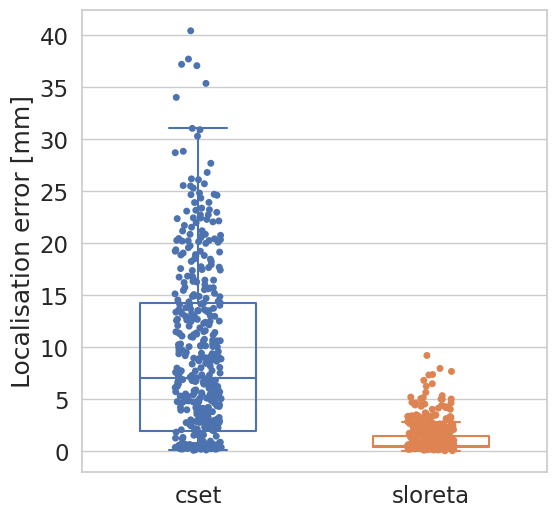

In [25]:
distance = error.copy()
for m in methods:
    distance[m] = [item[0] for item in distance[m]]

distance = pd.DataFrame(distance)
distance = distance.groupby("loc").mean()*1000

plt.figure(figsize=(6, 6))

ax  = sns.boxplot(data=distance, order=["cset", "sloreta"], fill=False, showfliers=False, width=0.5)
ax2 = sns.stripplot(data=distance, order=["cset", "sloreta"])

ax.set(ylabel="Localisation error [mm]")


print("Average difference: ", abs(distance["cset"].mean() - distance["sloreta"].mean()))
sp.stats.wilcoxon(distance["cset"].values, distance["sloreta"].values)

🌟 **Localization error by region** <br>
🛠️ **<font color=violet>Options</font>**:
- `method`: Which source imaging method to plot.


In [29]:
#################### Parameters ######################
method = "cset" 
######################################################

# source labels
src    = mm.utils.get_src_position(data["fwd"]["src"])*1000 + data["cras"]
labels = np.array(data["parc"].label_points(src))

# associate each region to distance error
signal    = np.zeros(src.shape[0])
signal[:] = np.nan

for l, v in zip(distance.index, distance[method]):
    signal[labels == l] = v

# plot
mm.viz.plot_brain_signal(data["fwd"]["src"], signal, cmap="reds").show()

Widget(value='<iframe src="http://localhost:33515/index.html?ui=P_0x749d7d132cd0_3&reconnect=auto" class="pyvi…

🌟 **Correlation**

In [58]:
correlation = error.copy()
correlation

{'cset': [(np.float64(0.21914051212426913), np.float64(0.3789916861893523)),
  (np.float64(0.2623852757066387), np.float64(0.4012288051289357)),
  (np.float64(0.2656746333669899), np.float64(0.37913796776315717)),
  (np.float64(0.4129827574324327), np.float64(0.4964314758712179)),
  (np.float64(0.33697997070211744), np.float64(0.42978190514604586)),
  (np.float64(0.3500445563676836), np.float64(0.45632547177910543)),
  (np.float64(0.2670333103592236), np.float64(0.38027968238773446)),
  (np.float64(0.3520470273181614), np.float64(0.4178180181128783)),
  (np.float64(0.35706064810380717), np.float64(0.4166031720928349)),
  (np.float64(0.23324861156226), np.float64(0.3787394346529439)),
  (np.float64(0.4335990334627225), np.float64(0.37630545456722475)),
  (np.float64(0.3378696339959872), np.float64(0.44640224182009)),
  (np.float64(0.35802555151435556), np.float64(0.39796413593422275)),
  (np.float64(0.31631346061956184), np.float64(0.41656825566275696)),
  (np.float64(0.327730284108579)

Average difference: 0.034472274270723524


WilcoxonResult(statistic=np.float64(1347.0), pvalue=np.float64(5.1141812114637424e-05))

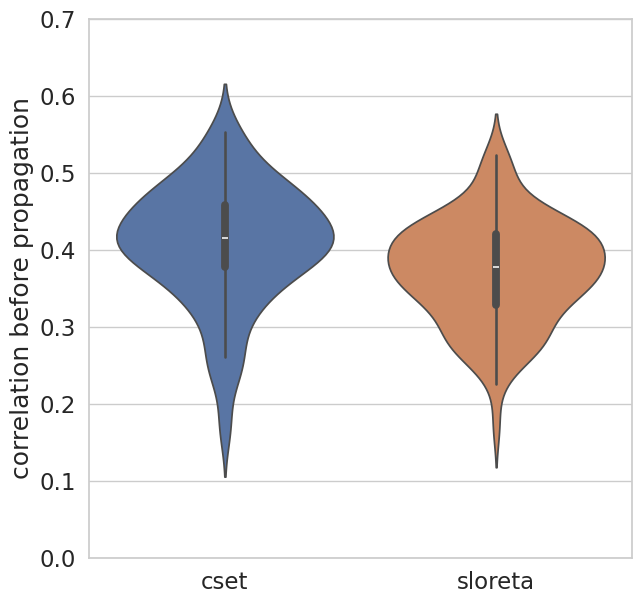

In [62]:
correlation = error.copy()
for m in methods:
    correlation[m] = [item[1] for item in correlation[m]]

correlation = pd.DataFrame(correlation)
correlation.groupby("loc").mean()

plt.figure(figsize=(7,7))
ax2 = sns.violinplot(data=correlation[methods])

plt.ylim(0, 0.7)
plt.ylabel("correlation before propagation")

print(f"Average difference: {abs(correlation['cset'].mean() - correlation['sloreta'].mean())}")

sp.stats.wilcoxon(correlation["cset"].values, correlation["sloreta"].values)

# Step Wise Run

Evaluate from 1 single simulation.

## 📦 Imports

In [1]:
import mindmap as mm
import numpy as np
import seaborn as sns
import pandas as pd
import scipy as sp
import matplotlib.pyplot as plt
import mne 

In [2]:
def compute_error(recon, area, src, brain, eeg, cras):
    """
    Compute source localisation at 50% rising phase and correlation at peak phase.

    Parameters
    ----------
    recon: mne.SourceEstimate.
        Reconstruction at 50% rising phase [0] and peak phase [1]

    area:
        Location of source. 

    src: mne.SourceSpace
        Dipole locations.

    brain:
        Ground truth.

    Returns
    -------
    dist: float
        Distance error to source location.

    corr: float
        Correlation with ground truth at peak phase.
    """

    # measure error distance
    estimate = mm.utils.select_source_estimate(recon, src, tp=0)
    dist = mm.utils.measure_distance(estimate, area, cras=cras)

    # measure correlation
    _, peak = mm.utils.eeg_rising_phase(eeg, 1)
    gt = np.abs(brain.data[:,peak])
    gt = (gt -gt.mean())/np.std(gt)

    tmp = np.abs(recon.data[:,1])
    tmp = (tmp - tmp.mean())/np.std(tmp)

    corr = np.sum(gt*tmp)/(gt.shape[0]-1)

    return dist, corr

## 🧠 Data

In [3]:
# configuration
config = mm.io.read_config("../../configurations/simf.yml")
sub    = config["SUBS"][0]

# simulation parameters
methods = ["cset", "sloreta"]

# data
data = mm.io.read_dataset(sub, "fwd", "eeg", "sc", "cst", "parc", "cras", "ctx")

# plot
sns.set_theme(font_scale=1.2)
sns.set_style("whitegrid")

Coregistered EEG found
DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- parc
- cras
- fwd
- sc
- ctx
- eeg
- cst
Missing objects:


## Generate 1 simulation

In [4]:
# select source locations
source_regions = mm.utils.select_sources(sub, spacing="ico1", mask=data["ctx"], cras=data["cras"])
source_regions = data["parc"].label_points(source_regions)
location       = np.random.choice(source_regions)

spike = mm.utils.create_source_spike(
        duration  = 1,                                  # [s] 
        sfreq     = data["eeg"].info["sfreq"],    # [Hz] 
        stype     = "mex",                              # mexican hat signal 
        amplitude = 1e-8,                               # [A] (10-8 -> 10 [nA]) 
)

spike_activity = mm.utils.generate_spike_activity(
        src      = data["fwd"]["src"],
        sc       = data["sc"],
        parc     = data["parc"],
        spike    = spike,
        location = location, 
        dw       = 0.25,        # propagation weight [0-1]
        dt       = 50,         # time delay [ms]
        sfreq    = data["eeg"].info["sfreq"],
        cras     = data["cras"],
    )

brain_noise, eeg_noise = mm.utils.generate_scaled_noise(
    data       = spike_activity,
    fwd        = data["fwd"],
    target_snr = 15,
    ratio      = 0.9, 
)

brain, eeg = mm.utils.simulate_eeg(
    brain_activity = spike_activity,
    fwd            = data["fwd"],
    eeg_temp       = data["eeg"],
    brain_noise    = brain_noise,
    eeg_noise      = eeg_noise, 
    sub            = sub,
)

area = data["parc"].create_mask(location)

#### 🌟 Brain

In [5]:
mm.viz.plot_brain(data["fwd"]["src"], brain, cmap="bwr").show()

Widget(value='<iframe src="http://localhost:35665/index.html?ui=P_0x79f0ae840550_0&reconnect=auto" class="pyvi…

#### 🌟 EEG

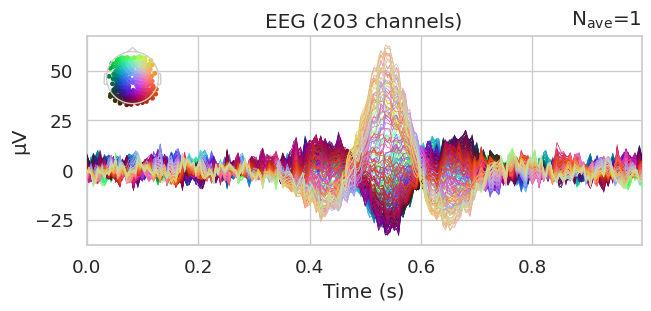

In [6]:
_ = eeg.plot()

## Perform Source Reconstruction

In [7]:
cset    = mm.cset(eeg=eeg, fwd=data["fwd"], cst=data["cst"], lam=0.01, dw=0.5, sub=sub)
sloreta = mm.sloreta(eeg=eeg, fwd=data["fwd"], lam=0.01)

EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.


#### 🌟 Source Reconstruction

In [ ]:
recon = cset 
phase = 0

plotter = mm.viz.plot_brain(data["fwd"]["src"], overlay=area, cras=data["cras"], signal=np.abs(recon.data[:,125]), show_max=True)
plotter.show()

Widget(value='<iframe src="http://localhost:42243/index.html?ui=P_0x79bd9f8ec8d0_3&reconnect=auto" class="pyvi…

In [1]:
classifier = 0.23

def classify_sources(reference, estimations):
    TP = (reference == 1) & (estimations == 1)
    TN = (reference == 0) & (estimations == 0)
    FP = (reference == 0) & (estimations == 1)
    FN = (reference == 1) & (estimations == 0)

    labels = np.zeros_like(reference, dtype=np.uint8)
    labels[TP] = 3
    labels[TN] = 0
    labels[FP] = 1
    labels[FN] = 2

    return labels

def binarize_activity(activity, classifier=0.5):
    activity      = activity.copy()
    activity.data = np.abs(activity.data) / np.max(np.abs(activity.data))
    activity.data = (activity.data > classifier).astype(np.uint8)

    return activity

brain_bin = binarize_activity(brain, classifier=classifier)
cset_bin  = binarize_activity(cset, classifier=classifier)
sloreta   = binarize_activity(sloreta, classifier=classifier)

cset_match = classify_sources(brain_bin, cset_bin)
sloreta_match = classify_sources(brain_bin, sloreta_bin)

mm.viz.plot_brain(data["fwd"]["src"], cset_match, cmap="bwr").show()

NameError: name 'brain' is not defined

## Evaluate Performance

In [20]:
dist, corr = compute_error(cset, area, data["fwd"]["src"], brain, eeg, cras=data["cras"])
print(f"CSET error: {dist*1000} [mm] and {corr}")

dist, corr = compute_error(sloreta, area, data["fwd"]["src"], brain ,eeg, cras=data["cras"])
print(f"sLORETA error: {dist*1000} [mm] and {corr}")

TypeError: cannot unpack non-iterable numpy.float64 object

In [21]:
evaluation1 = pd.DataFrame(mm.utils.binary_classification(brain, cset))
evaluation2 = pd.DataFrame(mm.utils.binary_classification(brain, sloreta))



[[False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]]
[[False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]]


<Axes: >

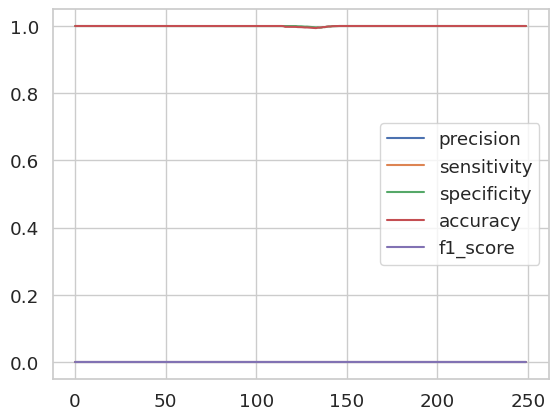

In [22]:
evaluation1.plot()

<Axes: >

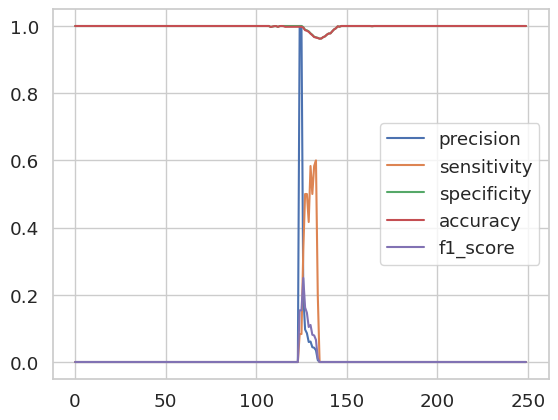

In [23]:
evaluation2.plot()